Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Learned Q-Table:
          Up       Down      Left     Right
0   0.575917   1.087382  0.598815  1.809800
1   1.774792   1.749632  0.527895  3.122000
2   3.057291   4.580000  1.699748  4.302108
3   2.066031   6.174070  0.212160  1.979251
4  -1.837461   2.718970 -1.690889 -0.982407
5   0.000000   0.000000  0.000000  0.000000
6   3.007138   6.200000  4.538392  6.155161
7   3.500845   7.999977  3.474518  5.537452
8  -0.610888   4.378958  0.498846  0.300240
9   0.000000   0.000000  0.000000  0.000000
10  4.515246   7.919629  6.144086  8.000000
11  6.171623  10.000000  6.095296  7.975913
12  0.052419   3.162327  1.940703  6.130798
13  5.050359   4.684414  2.790834  7.984607
14  5.272188   6.414807  4.967308  9.999383
15  0.000000   0.000000  0.000000  0.000000

Optimal Policy:
[['Right' 'Right' 'Down' 'Down']
 ['Down' 'X' 'Down' 'Down']
 ['Down' 'X' 'Right' 'Down']
 ['Right' 'Right' 'Right' 'G']]

Total Episodes: 1000
Successful Episodes: 997
Success Rate: 99.7 %


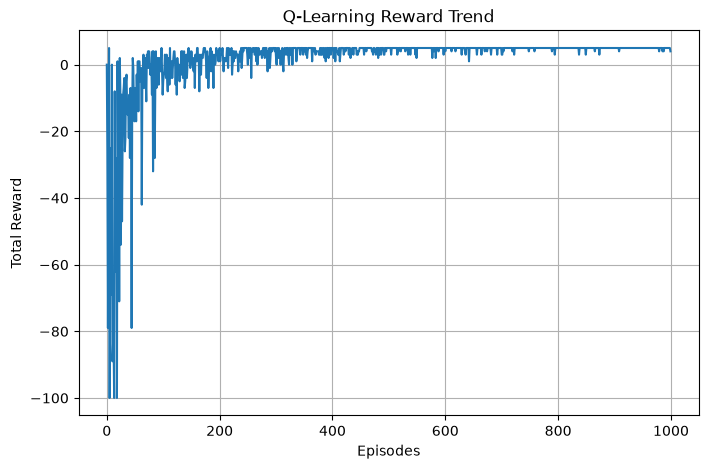


Grid World:
S = Start, G = Goal, X = Obstacle
[['S' '.' '.' '.']
 ['.' 'X' '.' '.']
 ['.' 'X' '.' '.']
 ['.' '.' '.' 'G']]


In [2]:

%pip install numpy matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Define the Grid World environment

rows = 4
cols = 4

start_state = (0, 0)
goal_state = (3, 3)

obstacles = [(1, 1), (2, 1)]

actions = ["Up", "Down", "Left", "Right"]

action_moves = {
    "Up": (-1, 0),
    "Down": (1, 0),
    "Left": (0, -1),
    "Right": (0, 1)
}

def get_next_state(state, action):

    move = action_moves[action]

    new_row = state[0] + move[0]
    new_col = state[1] + move[1]

    if (new_row < 0 or new_row >= rows or
        new_col < 0 or new_col >= cols):
        return state

    if (new_row, new_col) in obstacles:
        return state

    return (new_row, new_col)

def get_reward(state):

    if state == goal_state:
        return 10

    return -1

# Step 2: Initialize the Q-table

states = [(r, c) for r in range(rows) for c in range(cols)]

q_table = np.zeros((rows * cols, len(actions)))

def state_index(state):
    return state[0] * cols + state[1]

# Step 3: Set Q-Learning parameters

learning_rate = 0.1
discount_factor = 0.9
epsilon = 1.0
epsilon_decay = 0.995
min_epsilon = 0.01

episodes = 1000

rewards_per_episode = []
success_count = 0

# Step 4 and 5: Apply epsilon-greedy strategy and update Q-values

for episode in range(episodes):

    state = start_state
    total_reward = 0

    for step in range(100):

        current_index = state_index(state)

        # Epsilon-greedy action selection
        if np.random.random() < epsilon:
            action_index = np.random.randint(len(actions))
        else:
            action_index = np.argmax(q_table[current_index])

        action = actions[action_index]

        # Perform action
        next_state = get_next_state(state, action)

        reward = get_reward(next_state)

        next_index = state_index(next_state)

        # Q-Learning update rule
        q_table[current_index, action_index] = (
            q_table[current_index, action_index] +
            learning_rate * (
                reward +
                discount_factor * np.max(q_table[next_index]) -
                q_table[current_index, action_index]
            )
        )

        state = next_state
        total_reward += reward

        if state == goal_state:
            success_count += 1
            break

    rewards_per_episode.append(total_reward)

    # Reduce exploration over time
    epsilon = max(min_epsilon, epsilon * epsilon_decay)

# Step 6: Display the learned Q-table

print("Learned Q-Table:")
print(pd.DataFrame(q_table, columns=actions))

# Step 7: Display the optimal policy

print("\nOptimal Policy:")

policy = np.full((rows, cols), " ", dtype=object)

for state in states:

    if state == goal_state:
        policy[state] = "G"

    elif state in obstacles:
        policy[state] = "X"

    else:
        best_action = np.argmax(q_table[state_index(state)])
        policy[state] = actions[best_action]

print(policy)

print("\nTotal Episodes:", episodes)
print("Successful Episodes:", success_count)
print("Success Rate:", round(success_count / episodes * 100, 2), "%")

# Plot reward trend
plt.figure(figsize=(8, 5))

plt.plot(rewards_per_episode)

plt.title("Q-Learning Reward Trend")
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.grid(True)
plt.show()

# Display the Grid World
print("\nGrid World:")
print("S = Start, G = Goal, X = Obstacle")

grid = np.full((rows, cols), ".", dtype=object)

grid[start_state] = "S"
grid[goal_state] = "G"

for obstacle in obstacles:
    grid[obstacle] = "X"

print(grid)
